In [2]:
%pip install -q -U transformers accelerate scikit-learn pandas matplotlib tqdm # -on
#/ %pip install -q -U transformers accelerate scikit-learn pandas matplotlib tqdm -off

Menginstal library yang dibutuhkan untuk menjalankan BioBERT.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from transformers import BertTokenizer, AutoModelForSequenceClassification
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Device: cuda
GPU: Tesla T4


Memanggil library dan menentukan perangkat yang digunakan, CPU atau GPU.

In [4]:
uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("Please upload the mtsamples.csv file.")

df = pd.read_csv(csv_files[0])
print("Dataset shape:", df.shape)
display(df.head())


Saving mtsamples.csv to mtsamples (2).csv
Dataset shape: (4999, 6)


,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


Upload dataset mtsamples.csv yang berisi deskripsi medis.

In [5]:
required_columns = ["description", "medical_specialty"]
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df = df[required_columns].dropna().copy()
df["description"] = df["description"].astype(str).str.strip()
df["medical_specialty"] = df["medical_specialty"].astype(str).str.strip()
df = df[(df["description"] != "") & (df["medical_specialty"] != "")].reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
display(df["medical_specialty"].value_counts())
print("Number of medical specialties:", df["medical_specialty"].nunique())


Cleaned dataset shape: (4993, 2)


medical_specialty
Surgery                          1102
Consult - History and Phy.        514
Cardiovascular / Pulmonary        372
Orthopedic                        355
Radiology                         273
General Medicine                  259
Gastroenterology                  229
Neurology                         222
SOAP / Chart / Progress Notes     166
Obstetrics / Gynecology           160
Urology                           158
Discharge Summary                 108
ENT - Otolaryngology               98
Neurosurgery                       94
Hematology - Oncology              90
Ophthalmology                      83
Nephrology                         81
Emergency Room Reports             75
Pediatrics - Neonatal              70
Pain Management                    62
Psychiatry / Psychology            53
Office Notes                       51
Podiatry                           47
Dermatology                        29
Dentistry                          27
Cosmetic / Plastic Surgery      

Number of medical specialties: 40


Membersihkan data dan menghapus nilai kosong.

In [6]:
label_encoder = LabelEncoder()
df["label"] = label_encoder.fit_transform(df["medical_specialty"])

texts = df["description"].tolist()
labels = df["label"].to_numpy()

num_labels = len(label_encoder.classes_)
print("Number of classes:", num_labels)
print("Classes:", list(label_encoder.classes_))


Number of classes: 40
Classes: ['Allergy / Immunology', 'Autopsy', 'Bariatrics', 'Cardiovascular / Pulmonary', 'Chiropractic', 'Consult - History and Phy.', 'Cosmetic / Plastic Surgery', 'Dentistry', 'Dermatology', 'Diets and Nutritions', 'Discharge Summary', 'ENT - Otolaryngology', 'Emergency Room Reports', 'Endocrinology', 'Gastroenterology', 'General Medicine', 'Hematology - Oncology', 'Hospice - Palliative Care', 'IME-QME-Work Comp etc.', 'Lab Medicine - Pathology', 'Letters', 'Nephrology', 'Neurology', 'Neurosurgery', 'Obstetrics / Gynecology', 'Office Notes', 'Ophthalmology', 'Orthopedic', 'Pain Management', 'Pediatrics - Neonatal', 'Physical Medicine - Rehab', 'Podiatry', 'Psychiatry / Psychology', 'Radiology', 'Rheumatology', 'SOAP / Chart / Progress Notes', 'Sleep Medicine', 'Speech - Language', 'Surgery', 'Urology']


Mengubah kategori spesialisasi medis menjadi angka agar bisa diproses model

In [8]:
from transformers import BertForSequenceClassification, BertTokenizer

MODEL_NAME = "dmis-lab/biobert-base-cased-v1.1"

# Use explicit BERT classes since BioBERT's config lacks the metadata required for AutoClasses
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels
)

model.to(device)

print("BioBERT tokenizer and classification model are ready.")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dmis-lab/biobert-base-cased-v1.1
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

BioBERT tokenizer and classification model are ready.


Memuat tokenizer dan model BioBERT dari Hugging Face.

In [9]:
MAX_LEN = 128

encodings = tokenizer(
    texts,
    truncation=True,
    padding="max_length",
    max_length=MAX_LEN,
    return_tensors="pt"
)

input_ids = encodings["input_ids"]
attention_masks = encodings["attention_mask"]
labels_tensor = torch.tensor(labels, dtype=torch.long)

print("Input IDs shape:", input_ids.shape)
print("Attention masks shape:", attention_masks.shape)


Input IDs shape: torch.Size([4993, 128])
Attention masks shape: torch.Size([4993, 128])


Mengubah teks medis menjadi token atau angka yang dapat dipahami model.

In [10]:
indices = np.arange(len(labels))
class_counts = np.bincount(labels)
stratify_labels = labels if len(class_counts) > 1 and class_counts.min() >= 2 else None

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.1,
    random_state=2020,
    stratify=stratify_labels
)

class MedicalDataset(Dataset):
    def __init__(self, input_ids, attention_masks, labels, indices):
        self.input_ids = input_ids[indices]
        self.attention_masks = attention_masks[indices]
        self.labels = labels[indices]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_masks[idx],
            "labels": self.labels[idx]
        }

train_dataset = MedicalDataset(input_ids, attention_masks, labels_tensor, train_idx)
val_dataset = MedicalDataset(input_ids, attention_masks, labels_tensor, val_idx)

BATCH_SIZE = 8 if device.type == "cuda" else 4

train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
validation_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))


Training samples: 4493
Validation samples: 500


Membagi dataset menjadi data training dan validation.

In [17]:
EPOCHS = 3
LEARNING_RATE = 2e-5

optimizer = AdamW(model.parameters(), lr=LEARNING_RATE)
train_loss_history = []
validation_accuracy_history = []

for epoch in range(EPOCHS):
    model.train()
    total_train_loss = 0

    progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch + 1}/{EPOCHS}")
    for batch in progress_bar:
        optimizer.zero_grad()

        batch = {key: value.to(device) for key, value in batch.items()}
        outputs = model(**batch)
        loss = outputs.loss

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_train_loss += loss.item()
        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    average_train_loss = total_train_loss / max(len(train_dataloader), 1)
    train_loss_history.append(average_train_loss)

    model.eval()
    all_predictions = []
    all_true_labels = []

    with torch.no_grad():
        for batch in validation_dataloader:
            batch = {key: value.to(device) for key, value in batch.items()}
            outputs = model(
                input_ids=batch["input_ids"],
                attention_mask=batch["attention_mask"]
            )
            predictions = torch.argmax(outputs.logits, dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_true_labels.extend(batch["labels"].cpu().numpy())

    val_accuracy = accuracy_score(all_true_labels, all_predictions)
    validation_accuracy_history.append(val_accuracy)

    print(f"Epoch {epoch + 1}: Training Loss = {average_train_loss:.4f}, "
          f"Validation Accuracy = {val_accuracy:.4f}")


Epoch 1/3:   0%|          | 0/562 [00:00<?, ?it/s]

Epoch 1: Training Loss = 1.4891, Validation Accuracy = 0.2920


Epoch 2/3:   0%|          | 0/562 [00:00<?, ?it/s]

Epoch 2: Training Loss = 1.3806, Validation Accuracy = 0.2260


Epoch 3/3:   0%|          | 0/562 [00:00<?, ?it/s]

Epoch 3: Training Loss = 1.2979, Validation Accuracy = 0.2400


Melatih BioBERT agar dapat mengenali dan mengklasifikasikan spesialisasi medis.

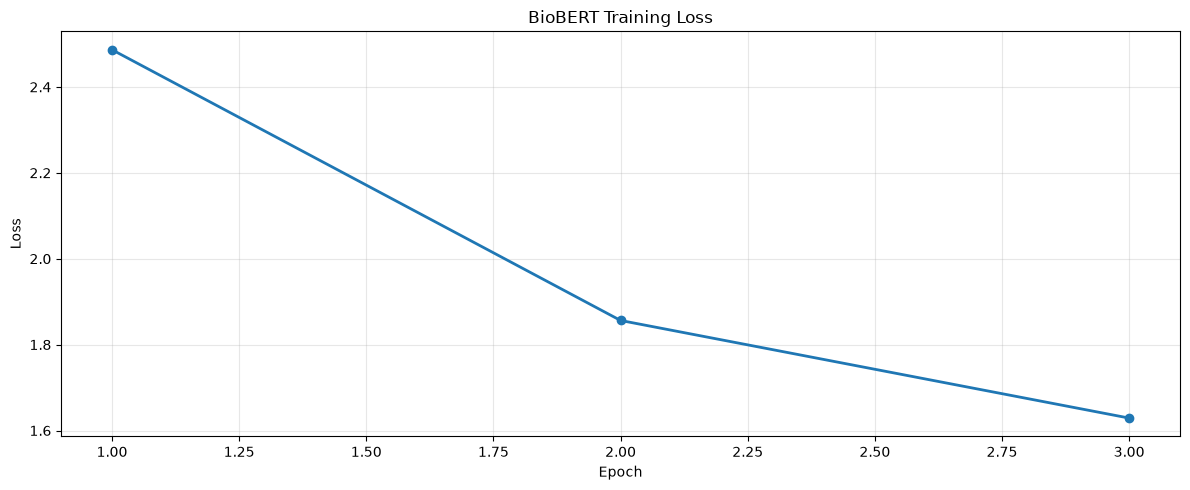

In [15]:
plt.figure(figsize=(12, 5))

# Corrected the variable name from batch_loss_history to train_loss_history
plt.plot(
    range(1, len(train_loss_history) + 1),
    train_loss_history,
    marker='o',
    linewidth=2
)

plt.title("BioBERT Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Menampilkan grafik perubahan nilai loss selama proses training.

In [13]:
print("Final validation accuracy:", f"{validation_accuracy_history[-1]:.4f}")
print("\nClassification report:")
print(classification_report(
    all_true_labels,
    all_predictions,
    labels=np.arange(num_labels),
    target_names=label_encoder.classes_,
    zero_division=0
))

Final validation accuracy: 0.2660

Classification report:
                               precision    recall  f1-score   support

         Allergy / Immunology       0.00      0.00      0.00         1
                      Autopsy       0.00      0.00      0.00         1
                   Bariatrics       0.00      0.00      0.00         2
   Cardiovascular / Pulmonary       0.38      0.68      0.49        37
                 Chiropractic       0.00      0.00      0.00         1
   Consult - History and Phy.       0.17      0.29      0.21        51
   Cosmetic / Plastic Surgery       0.00      0.00      0.00         3
                    Dentistry       0.33      0.33      0.33         3
                  Dermatology       0.00      0.00      0.00         3
         Diets and Nutritions       0.00      0.00      0.00         1
            Discharge Summary       0.00      0.00      0.00        11
         ENT - Otolaryngology       0.36      0.40      0.38        10
       Emergency R

Menampilkan akurasi dan hasil evaluasi model.